In [ ]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from tqdm import tqdm

In [ ]:
import joblib
X_train = joblib.load('/content/drive/MyDrive/CW_NC/X_train_prob.pkl')

y_train = joblib.load('/content/drive/MyDrive/CW_NC/y_train_enc.pkl')

X_test = joblib.load('/content/drive/MyDrive/CW_NC/X_test_prob.pkl')

y_test = joblib.load('/content/drive/MyDrive/CW_NC/y_test_enc.pkl')


In [ ]:
from sklearn.model_selection import train_test_split
X_test, X_val, y_test, y_val = train_test_split(
    X_test,
    y_test,
    test_size=0.50,
    stratify=y_test,
    random_state=42
)

In [ ]:
from sklearn import svm

DEFAULT LinearSVC

In [ ]:
model = svm.LinearSVC(multi_class='ovr', C=1.0, max_iter=10000)
model.fit(X_train, y_train)
#10 classifers for 10 classses

LinearSVC(max_iter=10000)

In [ ]:
y_pred=model.predict(X_val)

In [ ]:
from sklearn.metrics import jaccard_score

score = jaccard_score(y_pred, y_val, average='macro')
score


np.float64(0.6330856241788775)

#### Grid Search

##### LinearSVC

In [ ]:
param_grid_linear = {
    "C": [0.01, 0.1, 1, 5, 10, 50, 100],
    "class_weight": ['balanced']
}

In [ ]:
from sklearn.metrics import jaccard_score, make_scorer, f1_score
jaccard_macro_scorer = make_scorer(jaccard_score, average='macro')
scorer = make_scorer(f1_score, average='weighted')

In [ ]:
from sklearn.model_selection import GridSearchCV

grid_search_linear = GridSearchCV(
    estimator=svm.LinearSVC(random_state=42),
    param_grid=param_grid_linear, scoring=jaccard_macro_scorer,cv=5,return_train_score=True)
grid_search_linear.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=LinearSVC(random_state=42),
             param_grid={'C': [0.01, 0.1, 1, 5, 10, 50, 100],
                         'class_weight': ['balanced']},
             return_train_score=True,
             scoring=make_scorer(jaccard_score, response_method='predict', average=macro))

In [ ]:
grid_search_linear.best_params_

{'C': 100, 'class_weight': 'balanced'}

In [ ]:
grid_search_linear.best_score_

np.float64(0.7268389545669355)

In [ ]:
results = pd.DataFrame(grid_search_linear.cv_results_)
results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_class_weight,params,split0_test_score,split1_test_score,split2_test_score,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.247444,0.012393,0.010119,0.000838,0.01,balanced,"{'C': 0.01, 'class_weight': 'balanced'}",0.440217,0.512565,0.490681,...,0.479668,0.023555,7,0.487687,0.482806,0.486461,0.487396,0.484751,0.485820,0.001823
1,0.287494,0.011669,0.009303,0.000180,0.10,balanced,"{'C': 0.1, 'class_weight': 'balanced'}",0.562000,0.612182,0.582265,...,0.590858,0.021650,6,0.600047,0.594531,0.601481,0.600197,0.593629,0.597977,0.003233
2,0.307947,0.010937,0.009341,0.000208,1.00,balanced,"{'C': 1, 'class_weight': 'balanced'}",0.637637,0.675318,0.651802,...,0.655771,0.017249,5,0.679440,0.673985,0.681462,0.682099,0.676758,0.678749,0.003024
3,0.325343,0.016145,0.009405,0.000438,5.00,balanced,"{'C': 5, 'class_weight': 'balanced'}",0.697117,0.726570,0.685847,...,0.694751,0.020849,4,0.731616,0.729236,0.733955,0.723954,0.741202,0.731993,0.005675
4,0.368053,0.032917,0.013298,0.003648,10.00,balanced,"{'C': 10, 'class_weight': 'balanced'}",0.700608,0.734305,0.694367,...,0.705126,0.016316,3,0.762063,0.752463,0.761580,0.754093,0.763323,0.758704,0.004497
5,0.511439,0.020358,0.016038,0.002408,50.00,balanced,"{'C': 50, 'class_weight': 'balanced'}",0.706316,0.758416,0.700496,...,0.725057,0.020832,2,0.807538,0.813867,0.822173,0.810247,0.821915,0.815148,0.005979
6,0.649298,0.146652,0.013951,0.003261,100.00,balanced,"{'C': 100, 'class_weight': 'balanced'}",0.704907,0.759127,0.702774,...,0.726839,0.022946,1,0.829490,0.843530,0.842392,0.841616,0.849242,0.841254,0.006462


In [ ]:
score_comparison = results[[
    'param_C',
    'mean_train_score',
    'mean_test_score',
    'std_test_score'
]]

# Sort by the test score to see the best performers
print(score_comparison.sort_values(by='mean_test_score', ascending=False))

   param_C  mean_train_score  mean_test_score  std_test_score
6   100.00          0.841254         0.726839        0.022946
5    50.00          0.815148         0.725057        0.020832
4    10.00          0.758704         0.705126        0.016316
3     5.00          0.731993         0.694751        0.020849
2     1.00          0.678749         0.655771        0.017249
1     0.10          0.597977         0.590858        0.021650
0     0.01          0.485820         0.479668        0.023555


In [ ]:
from matplotlib import pyplot as plt

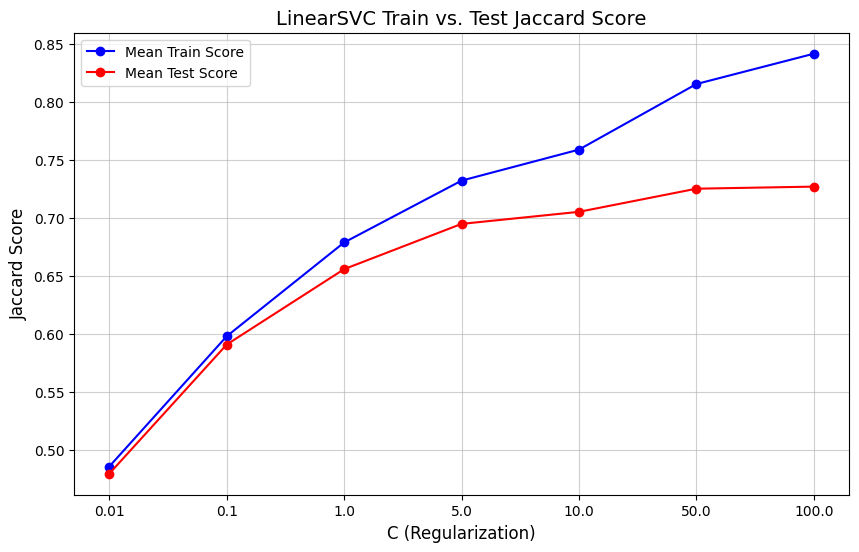

In [ ]:
#AI was used to plot this graph

x_axis = results['param_C'].astype(str)

# 2. Plotting
plt.figure(figsize=(10, 6))

plt.plot(x_axis, results['mean_train_score'], label='Mean Train Score', marker='o', color='blue')
plt.plot(x_axis, results['mean_test_score'], label='Mean Test Score', marker='o', color='red')

plt.title('LinearSVC Train vs. Test Jaccard Score', fontsize=14)
plt.xlabel('C (Regularization)', fontsize=12)
plt.ylabel('Jaccard Score', fontsize=12)
plt.legend()
plt.grid(alpha=0.6)

plt.show()

#Final Model

In [ ]:
model = svm.LinearSVC(multi_class='ovr', C=5, max_iter=10000)  #optimised C=5
model.fit(X_train, y_train)

LinearSVC(C=5, max_iter=10000)

In [ ]:
joblib.dump(model, 'LinearSVC_model.pkl')

['LinearSVC_model.pkl']